# AI651 PA2 · Question 2 · Notebook 2 — Baseline ConvLSTM (model A)

Trains model A with seeds 0 and 1 (30 epochs each), then produces **Table 2** and **Figure 2**.
This notebook only evaluates at 1× on the original clips, so no "Testing the Baseline"
experiment runs here.

**If the session disconnects:** reconnect (GPU runtime), then run the notebook again from the
top. Finished runs are loaded from Drive, an interrupted run continues from its last checkpoint
(end of every epoch and every 5 minutes inside an epoch), and cached metrics are not recomputed.

In [1]:
# 0) Drive, code and GPU -- run this first in every session
PROJECT = "/content/drive/MyDrive/AI651_PA2"   # data, checkpoints, results, figures live here
UPDATE_CODE = False   # True -> upload pa2_code.zip again (e.g. after you edit a script)

from google.colab import drive
drive.mount("/content/drive")

import os, sys, io, zipfile
CODE_DIR = os.path.join(PROJECT, "code")
os.makedirs(CODE_DIR, exist_ok=True)
if UPDATE_CODE or not os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")):
    from google.colab import files
    print("Upload pa2_code.zip (or the individual pa2/*.py files). "
          "It is stored on Drive, so this is only needed once.")
    for name, blob in files.upload().items():
        if name.endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(blob)).extractall(CODE_DIR)
        elif name.endswith(".py"):
            os.makedirs(os.path.join(CODE_DIR, "pa2"), exist_ok=True)
            clean = name.split(" (")[0].removesuffix(".py") + ".py"   # Colab renames "x (1).py"
            with open(os.path.join(CODE_DIR, "pa2", clean), "wb") as f:
                f.write(blob)
assert os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")), "pa2 package not found on Drive"
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
for m in [m for m in list(sys.modules) if m == "pa2" or m.startswith("pa2.")]:
    del sys.modules[m]                         # always import the version on Drive

import numpy as np
import matplotlib.pyplot as plt
import pa2
from pa2 import config, data, models, train, evaluation, visuals, checks, tables, utils
from pa2.pipeline import Context
from pa2.utils import show_table
%matplotlib inline
print("pa2 version", pa2.__version__)

Mounted at /content/drive
pa2 version 1.0


In [2]:
ctx = Context(PROJECT)
ctx.load_data();   # first run: downloads Moving MNIST (~800 MB) to Drive; later runs load it from there

Device: Tesla T4 (15 GB), torch 2.11.0+cu130
Loading Moving MNIST (downloaded to Drive the first time) ...
{'train': (8000, 20, 1, 64, 64), 'val': (1000, 20, 1, 64, 64), 'test': (1000, 20, 1, 64, 64)}


## Train model A (seeds 0 and 1)

In [3]:
for seed in config.SEEDS:
    ctx.train("A", seed)

[A/seed0] epoch  1/30  loss 0.04610  12.2 s
[A/seed0] epoch  2/30  loss 0.03969  9.6 s
[A/seed0] epoch  3/30  loss 0.03867  9.7 s
[A/seed0] epoch  4/30  loss 0.03709  9.8 s
[A/seed0] epoch  5/30  loss 0.03518  9.9 s  val E5 0.03387
[A/seed0] epoch  6/30  loss 0.03355  9.9 s
[A/seed0] epoch  7/30  loss 0.03225  10.0 s
[A/seed0] epoch  8/30  loss 0.03117  10.1 s
[A/seed0] epoch  9/30  loss 0.03043  10.1 s
[A/seed0] epoch 10/30  loss 0.02987  10.1 s  val E5 0.02949
[A/seed0] epoch 11/30  loss 0.02938  10.1 s
[A/seed0] epoch 12/30  loss 0.02902  10.2 s
[A/seed0] epoch 13/30  loss 0.02848  10.3 s
[A/seed0] epoch 14/30  loss 0.02816  10.4 s
[A/seed0] epoch 15/30  loss 0.02783  10.4 s  val E5 0.02732
[A/seed0] epoch 16/30  loss 0.02729  10.5 s
[A/seed0] epoch 17/30  loss 0.02711  10.5 s
[A/seed0] epoch 18/30  loss 0.02657  10.5 s
[A/seed0] epoch 19/30  loss 0.02615  10.6 s
[A/seed0] epoch 20/30  loss 0.02595  10.6 s  val E5 0.02539
[A/seed0] epoch 21/30  loss 0.02558  10.6 s
[A/seed0] epoch 2

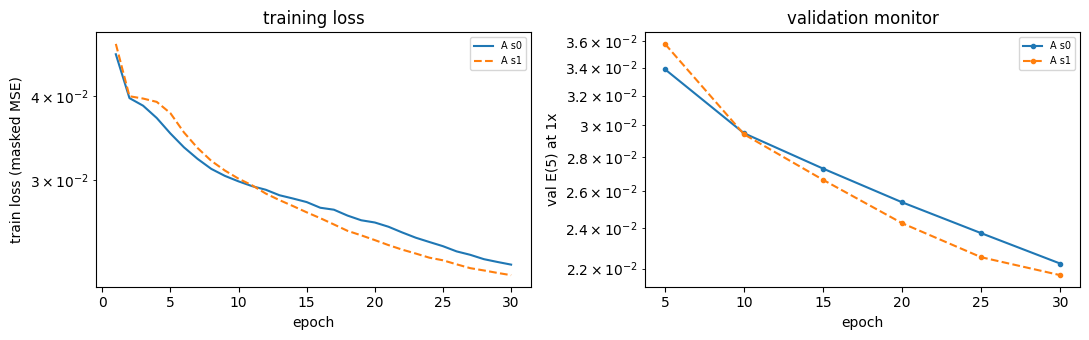

In [4]:
ctx.plot_curves(["A"], os.path.join(ctx.paths["figures"], "training_curves_A.png")); plt.show()

## Table 2 — model A vs Blank and Copy-last (test split, 1×, t = 1)

In [5]:
show_table(tables.table2(ctx))

| Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E(5) | Params |
|---|---|---|---|---|---|---|---|
| A | 0.0171 (0.0173, 0.0169) | 0.0205 (0.0208, 0.0201) | 0.0227 (0.0231, 0.0223) | 0.0245 (0.0248, 0.0241) | 0.0261 (0.0264, 0.0259) | 0.0222 (0.0225, 0.0219) | 480,784 |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |

Test split, 1×, t = 1. Learned model: mean (seed 0, seed 1).

## Figure 2 — input, prediction, ground truth
Picks two videos without overlap and the video with the largest digit overlap in the target
frames (overlap is detected from the drop in bright-pixel count). Set `FIG2_IDS` to choose
test videos yourself.

In [6]:
SEL_PATH = os.path.join(ctx.paths["results"], "selection.json")
sel = utils.load_json(SEL_PATH, {})        # example videos chosen for the figures (reused later)

test #7 (dataset idx 9007) | overlap (pixels) in target frames 6-10: [0 0 0 0 0]
test #12 (dataset idx 9012) | overlap (pixels) in target frames 6-10: [0 0 0 0 0]
test #539 (dataset idx 9539) | overlap (pixels) in target frames 6-10: [49 87 73 64 33]


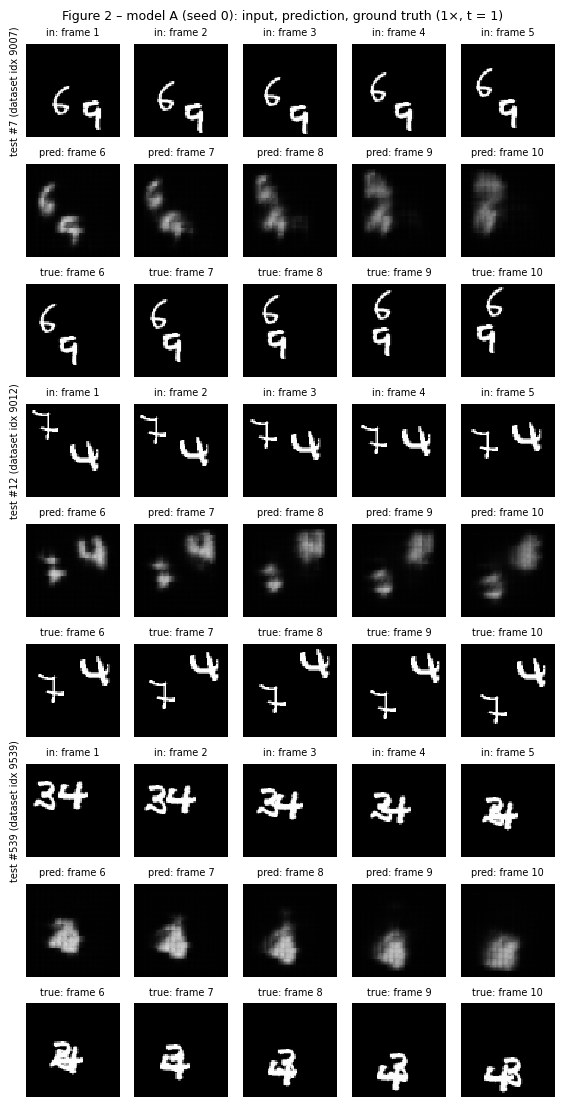

In [7]:
FIG2_IDS = None      # e.g. [12, 40, 7] (test indices 0-999)
if FIG2_IDS is None:
    FIG2_IDS = sel.get("fig2") or visuals.pick_fig2_videos(ctx.test)
sel["fig2"] = [int(i) for i in FIG2_IDS]
utils.atomic_json_save(sel, SEL_PATH)
for i in FIG2_IDS:
    ov = data.overlap_pixels(ctx.test[i])
    print(visuals.vid_label(i), "| overlap (pixels) in target frames 6-10:", ov[5:10].astype(int))
fig2 = visuals.figure2(ctx.model("A", 0), ctx.test, FIG2_IDS, ctx.device,
                       os.path.join(ctx.paths["figures"], "fig2_baseline_examples.png"))
plt.show()

## Before you continue
* Answer **Q2.3** and **Q2.4** using Table 2 and Figure 2.
* **Write your Q2.5 predictions now and commit them to your GitHub repository.**
  Notebook 3 runs the mirror, rotation and speed tests and will not start until you confirm
  this commit (the handout says commit times may be checked).